In [1]:
from google.colab import files
uploaded = files.upload()

Saving merged_dataset.csv to merged_dataset.csv


In [2]:
import pandas as pd
import numpy as np

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("merged_dataset.csv")
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (18115, 28)
  interaction_id user_id         timestamp day_of_week time_of_day  \
0        I000001   U0424  2026-07-01 00:39   Wednesday       night   
1        I000002   U0250  2026-07-01 00:43   Wednesday       night   
2        I000003   U0222  2026-07-01 01:34   Wednesday       night   
3        I000004   U0316  2026-07-01 02:24   Wednesday       night   
4        I000005   U0142  2026-07-01 02:31   Wednesday       night   

          mood  mood_intensity  energy_level activity_id      source  ...  \
0      anxiety               5             3        A002  rule_based  ...   
1      anxiety               3             4        A064      random  ...   
2  frustration               4             3        A061      random  ...   
3   loneliness               2             3        A018  rule_based  ...   
4       stress               4             3        A033  rule_based  ...   

  max_duration_pref  usual_energy              activity_title  \
0                10     

In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18115 entries, 0 to 18114
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   interaction_id        18115 non-null  object 
 1   user_id               18115 non-null  object 
 2   timestamp             18115 non-null  object 
 3   day_of_week           18115 non-null  object 
 4   time_of_day           18115 non-null  object 
 5   mood                  18115 non-null  object 
 6   mood_intensity        18115 non-null  int64  
 7   energy_level          18115 non-null  int64  
 8   activity_id           18115 non-null  object 
 9   source                18115 non-null  object 
 10  action                18115 non-null  object 
 11  rating                9049 non-null   float64
 12  helpful               18115 non-null  int64  
 13  split                 18115 non-null  object 
 14  age_group             18115 non-null  object 
 15  experience_level   

In [6]:
df.describe()

,mood_intensity,energy_level,rating,helpful,max_duration_pref,usual_energy,energy_required,duration_min,difficulty,needs_privacy
count,18115.000000,18115.000000,9049.000000,18115.000000,18115.000000,18115.000000,18115.000000,18115.000000,18115.000000,18115.000000
mean,3.005244,2.875021,3.424688,0.248247,10.981231,3.027105,1.262048,6.411041,1.310847,0.301794
std,1.142988,1.352620,1.025909,0.432008,5.970159,1.130828,0.534710,4.591093,0.539109,0.459049
min,1.000000,1.000000,1.000000,0.000000,5.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,2.000000,2.000000,3.000000,0.000000,5.000000,2.000000,1.000000,4.000000,1.000000,0.000000
50%,3.000000,3.000000,3.000000,0.000000,10.000000,3.000000,1.000000,5.000000,1.000000,0.000000
75%,4.000000,4.000000,4.000000,0.000000,20.000000,4.000000,1.000000,10.000000,2.000000,1.000000
max,5.000000,5.000000,5.000000,1.000000,20.000000,5.000000,3.000000,20.000000,3.000000,1.000000


In [7]:
print(df.isnull().sum()[df.isnull().sum() > 0])
print(df["helpful"].value_counts())

rating    9066
dtype: int64
helpful
0    13618
1     4497
Name: count, dtype: int64


In [8]:
print(df.groupby("action")["rating"].apply(lambda x: round(x.notna().mean(), 2)))

action
completed    1.0
dropped      0.0
skipped      0.0
Name: rating, dtype: float64


In [9]:
print(pd.crosstab(df["action"], df["helpful"]))

helpful       0     1
action               
completed  4552  4497
dropped    2530     0
skipped    6536     0


In [10]:
helpful_rate = df["helpful"].mean()
print("Helpful rate:", round(helpful_rate * 100, 2), "%")
print("Accuracy if model always says 0:", round((1 - helpful_rate) * 100, 2), "%")

Helpful rate: 24.82 %
Accuracy if model always says 0: 75.18 %


In [11]:
print(df.groupby("source")["helpful"].mean().round(3))

source
random        0.137
rule_based    0.362
Name: helpful, dtype: float64


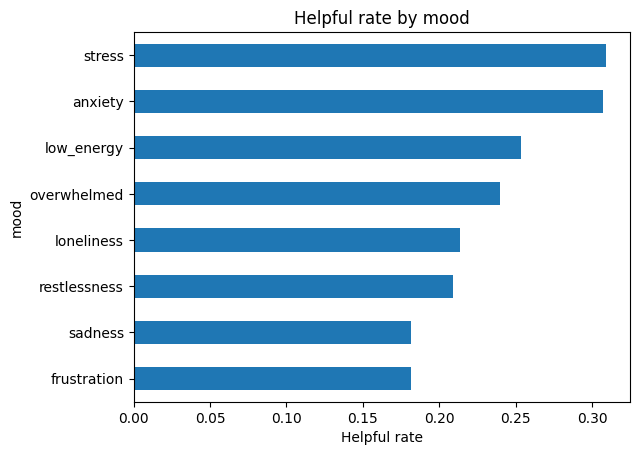

In [12]:
df.groupby("mood")["helpful"].mean().sort_values().plot(kind="barh", title="Helpful rate by mood")
plt.xlabel("Helpful rate")
plt.show()